# 01 Diffraction and Resolution

**Series:** Physics of the CHARA Array (Mount Wilson Observatory)
**Topic T1:** why a single telescope cannot resolve a star, and why two telescopes far apart can.

The CHARA Array, run by Georgia State University, has six 1 m telescopes in a Y shape. Telescope pairs are 34 m to 331 m apart. Light from each pair is combined to measure detail about 1000 times finer than one of its telescopes can see on its own.

This notebook answers three questions:

1. How big do stars look from Earth?
2. What sets the smallest detail a telescope can see?
3. Why does spreading telescopes apart beat building one bigger telescope?

Run the cells top to bottom. Cells with sliders are interactive.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, PowerNorm
from scipy.special import j1
from ipywidgets import interact, FloatSlider, FloatLogSlider, Dropdown

RAD_TO_MAS = 180 / np.pi * 3600 * 1000  # radians -> milliarcseconds
MAS_TO_RAD = 1 / RAD_TO_MAS

BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"
SLIDER_STYLE = {"handle_color": BLUE}  # visible knob on white backgrounds
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "lines.linewidth": 2,
})

## 1. How big are stars on the sky?

Astronomers measure size on the sky as an **angle**. A star of radius $R$ at distance $d$ spans an angular diameter

$$\theta = \frac{2R}{d} \quad \text{(radians)}$$

Stars are so small that the useful unit is the **milliarcsecond** (mas). One mas is 1/3,600,000 of a degree, about the size of a coin on the Moon seen from Earth.

Start with the Sun moved to 10 parsecs (32.6 light years), a typical distance to a nearby star.

In [2]:
R_SUN = 6.957e8        # m
PARSEC = 3.0857e16     # m

theta_sun_10pc = 2 * R_SUN / (10 * PARSEC) * RAD_TO_MAS
print(f"Sun at 10 pc: {theta_sun_10pc:.2f} mas")

Sun at 10 pc: 0.93 mas


Real stars measured by interferometers, including CHARA, span roughly 0.1 to 50 mas. The values below are approximate published angular diameters.

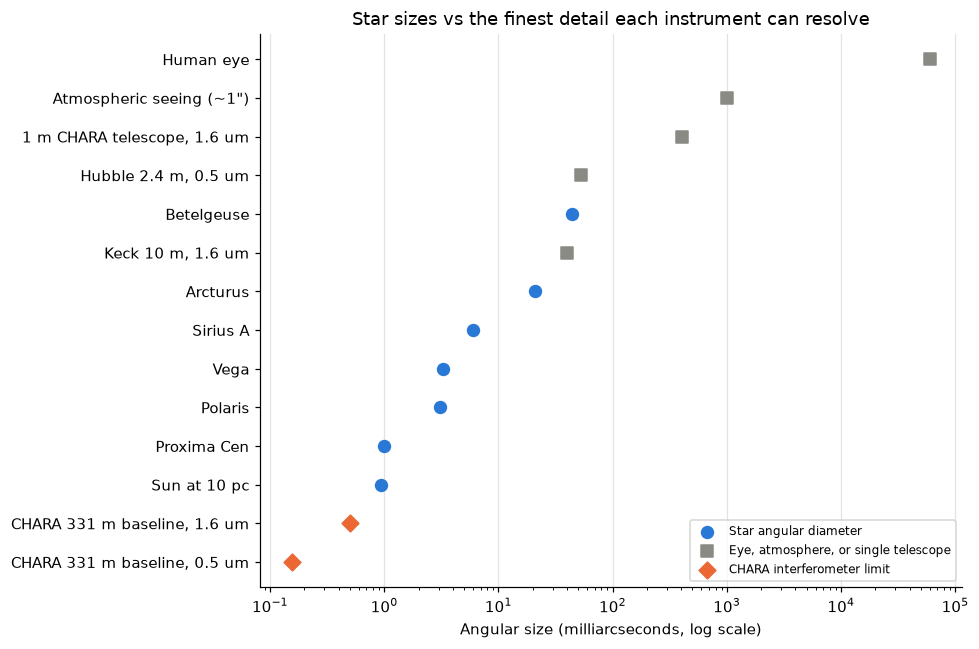

Human eye                          60000.00 mas
Atmospheric seeing (~1")            1000.00 mas
1 m CHARA telescope, 1.6 um          402.63 mas
Hubble 2.4 m, 0.5 um                  52.43 mas
Keck 10 m, 1.6 um                     40.26 mas
CHARA 331 m baseline, 1.6 um           0.50 mas
CHARA 331 m baseline, 0.5 um           0.16 mas


In [3]:
stars = {
    "Betelgeuse":   44.0,
    "Arcturus":     21.0,
    "Sirius A":      6.0,
    "Vega":          3.3,
    "Polaris":       3.1,
    "Proxima Cen":   1.0,
    "Sun at 10 pc": theta_sun_10pc,
}

def rayleigh_mas(wavelength_m, diameter_m):
    # Smallest resolvable angle for a circular aperture: 1.22 lambda / D
    return 1.22 * wavelength_m / diameter_m * RAD_TO_MAS

limits = {
    "Human eye":                     60_000,
    "Atmospheric seeing (~1\")":      1_000,
    "1 m CHARA telescope, 1.6 um":   rayleigh_mas(1.6e-6, 1.0),
    "Hubble 2.4 m, 0.5 um":          rayleigh_mas(0.5e-6, 2.4),
    "Keck 10 m, 1.6 um":             rayleigh_mas(1.6e-6, 10.0),
    "CHARA 331 m baseline, 1.6 um":  1.6e-6 / (2 * 331) * RAD_TO_MAS,
    "CHARA 331 m baseline, 0.5 um":  0.5e-6 / (2 * 331) * RAD_TO_MAS,
}

rows = sorted(
    [(v, k, "star") for k, v in stars.items()] +
    [(v, k, "chara" if "baseline" in k else "single") for k, v in limits.items()]
)
style = {
    "star":   dict(color=BLUE, marker="o", label="Star angular diameter"),
    "single": dict(color=GREY, marker="s", label="Eye, atmosphere, or single telescope"),
    "chara":  dict(color=ORANGE, marker="D", label="CHARA interferometer limit"),
}

fig, ax = plt.subplots(figsize=(9, 6))
for kind, st in style.items():
    pts = [(v, i) for i, (v, _, k) in enumerate(rows) if k == kind]
    ax.scatter(*zip(*pts), s=60, zorder=3, **st)
ax.set_yticks(range(len(rows)), [name for _, name, _ in rows])
ax.set_xscale("log")
ax.set_xlabel("Angular size (milliarcseconds, log scale)")
ax.set_title("Star sizes vs the finest detail each instrument can resolve")
ax.legend(loc="lower right", fontsize=8)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

for label, value in limits.items():
    print(f"{label:32s} {value:10.2f} mas")

**What the chart shows:** rows are sorted by angle, smallest at the bottom. Every star except Betelgeuse sits below every grey limit, so even Keck's 10 m mirror sees them as points. Only the CHARA limits (orange) reach below the smallest stars.

Two limits are mixed on that chart:

- **Diffraction** (the $1.22\,\lambda/D$ lines) is set by physics and the mirror size.
- **Atmospheric seeing** (~1000 mas) is turbulence blurring the image. Adaptive optics can remove much of it. Topic T7 covers this.

The rest of this notebook is about diffraction, the hard floor that no amount of engineering removes.

## 2. Diffraction: the image of a point is not a point

Light is a wave. When a wave passes through a circular opening of diameter $D$, it spreads out. A telescope focuses a distant point of light into a pattern called the **Airy pattern**: a bright core surrounded by faint rings.

The intensity at angle $\theta$ from the center is

$$I(\theta) = \left[\frac{2 J_1(x)}{x}\right]^2, \qquad x = \frac{\pi D \theta}{\lambda}$$

where $J_1$ is a Bessel function (it plays the role a sine plays for a slit). You don't need its details. What matters:

- The first dark ring is at $\theta = 1.22\,\lambda / D$.
- A **bigger mirror** ($D$ up) makes the pattern **smaller**.
- A **longer wavelength** ($\lambda$ up) makes the pattern **bigger**.

Any star smaller than the core looks identical to a point. Use the sliders to see how far the core is from star sizes.

In [4]:
def airy(theta_rad, diameter_m, wavelength_m):
    x = np.pi * diameter_m * theta_rad / wavelength_m
    x = np.where(x == 0, 1e-12, x)
    return (2 * j1(x) / x) ** 2


@interact(
    diameter_m=FloatLogSlider(value=1.0, base=10, min=-1, max=1.5, step=0.05,
                              description="D (m)", continuous_update=False, style=SLIDER_STYLE),
    wavelength_um=FloatSlider(value=1.6, min=0.4, max=2.5, step=0.05,
                              description="λ (µm)", continuous_update=False, style=SLIDER_STYLE),
    star=Dropdown(options=list(stars), value="Vega", description="Star"),
)
def show_airy(diameter_m, wavelength_um, star):
    lam = wavelength_um * 1e-6
    first_null_mas = rayleigh_mas(lam, diameter_m)
    extent = 3 * first_null_mas
    star_mas = stars[star]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))

    theta = np.linspace(-extent, extent, 2001)
    ax1.plot(theta, airy(theta * MAS_TO_RAD, diameter_m, lam), color=BLUE)
    ax1.axvspan(-star_mas / 2, star_mas / 2, color=ORANGE, alpha=0.35,
                label=f"{star} diameter ({star_mas:.2g} mas)")
    ax1.axvline(first_null_mas, color=GREY, linestyle="--", linewidth=1)
    ax1.axvline(-first_null_mas, color=GREY, linestyle="--", linewidth=1,
                label=f"first dark ring ±{first_null_mas:.3g} mas")
    ax1.set_xlabel("Angle from center (mas)")
    ax1.set_ylabel("Relative intensity")
    ax1.set_title("Airy pattern, 1D cut")
    ax1.legend(loc="upper right", fontsize=8)

    n = 401
    axis = np.linspace(-extent, extent, n)
    xx, yy = np.meshgrid(axis, axis)
    image = airy(np.hypot(xx, yy) * MAS_TO_RAD, diameter_m, lam)
    ax2.imshow(image, extent=[-extent, extent, -extent, extent], origin="lower",
               cmap="inferno", norm=LogNorm(vmin=1e-4, vmax=1))
    ax2.set_xlabel("mas")
    ax2.set_ylabel("mas")
    ax2.set_title("Airy pattern image (log brightness)")
    ax2.grid(False)

    plt.tight_layout()
    plt.show()
    ratio = 2 * first_null_mas / star_mas
    if ratio >= 1:
        print(f"Core is {ratio:,.1f}x wider than {star}. The star looks like a point.")
    else:
        print(f"{star} is {1 / ratio:.1f}x wider than the core. The disk is resolved.")

interactive(children=(FloatLogSlider(value=1.0, continuous_update=False, description='D (m)', max=1.5, min=-1.…

**Try this:**

- Set D to 30 m (the largest telescopes now being built). Vega is still far smaller than the core.
- Drop the wavelength to 0.4 µm. The pattern shrinks, which is why short wavelengths give sharper images.

## 3. The Rayleigh criterion: when do two points become two?

"Resolution" means telling two things apart. Put two equal point sources a small angle apart. Each makes its own Airy pattern, and the telescope sees their sum.

Lord Rayleigh's rule of thumb: two points are just resolved when the core of one sits on the first dark ring of the other, a separation of $1.22\,\lambda/D$. Closer than that, the two blur into one blob.

The slider sets the separation in units of $\lambda / D$, so the result holds for any telescope.

In [5]:
@interact(
    separation=FloatSlider(value=1.22, min=0.2, max=3.0, step=0.02,
                           description="sep (λ/D)", continuous_update=False, style=SLIDER_STYLE),
)
def show_two_points(separation):
    # Work in units of lambda/D, so D = lambda = 1.
    half = separation / 2
    u = np.linspace(-4, 4, 1601)
    left = airy(u + half, 1.0, 1.0)
    right = airy(u - half, 1.0, 1.0)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
    ax1.plot(u, left, color=GREY, linewidth=1, linestyle="--", label="each source")
    ax1.plot(u, right, color=GREY, linewidth=1, linestyle="--")
    ax1.plot(u, left + right, color=BLUE, label="what the telescope sees")
    ax1.set_xlabel("Angle (units of λ/D)")
    ax1.set_ylabel("Relative intensity")
    ax1.set_title(f"Two point sources {separation:.2f} λ/D apart")
    ax1.legend(fontsize=8)

    axis = np.linspace(-3, 3, 301)
    xx, yy = np.meshgrid(axis, axis)
    image = airy(np.hypot(xx + half, yy), 1, 1) + airy(np.hypot(xx - half, yy), 1, 1)
    ax2.imshow(image, extent=[-3, 3, -3, 3], origin="lower", cmap="inferno")
    ax2.set_xlabel("λ/D")
    ax2.set_ylabel("λ/D")
    ax2.set_title("Image")
    ax2.grid(False)
    plt.tight_layout()
    plt.show()

    lam, D = 1.6e-6, 1.0
    print(f"For a 1 m CHARA telescope at 1.6 µm, this separation is "
          f"{separation * lam / D * RAD_TO_MAS:.0f} mas.")

interactive(children=(FloatSlider(value=1.22, continuous_update=False, description='sep (λ/D)', max=3.0, min=0…

**Try this:** slide below about 0.9. The dip between the peaks disappears and the pair looks like one source.

## 4. The aperture shape sets the pattern

The Airy pattern is not special to round mirrors. The image of a point is always set by the **shape of the opening** that collects the light. The math link is the Fourier transform: the image of a point is the squared magnitude of the Fourier transform of the aperture. Topic T3 builds on this idea.

The cell below computes the image numerically for two openings:

- one 1 m circular mirror
- two 1 m mirrors whose centers are $B$ apart (the **baseline**)

The baseline here is limited to 10 m so the fringes are visible on a computer grid. CHARA's baselines are 34 to 331 m, so the real fringes are much finer.

In [6]:
N = 1024           # grid points per side
DX = 0.05          # metres per pupil pixel -> grid is 51 m wide
WAVELENGTH = 1.6e-6
PUPIL_AXIS = (np.arange(N) - N / 2) * DX
PX, PY = np.meshgrid(PUPIL_AXIS, PUPIL_AXIS)

# Angular pixel of the FFT image: lambda / (grid width)
ANGLE_PIX_MAS = WAVELENGTH / (N * DX) * RAD_TO_MAS


def disk(cx, diameter=1.0):
    return (np.hypot(PX - cx, PY) <= diameter / 2).astype(float)


def point_image(pupil):
    field = np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(pupil)))
    intensity = np.abs(field) ** 2
    return intensity / intensity.max()


@interact(
    baseline_m=FloatSlider(value=5.0, min=1.5, max=10.0, step=0.5,
                           description="B (m)", continuous_update=False, style=SLIDER_STYLE),
)
def show_two_apertures(baseline_m):
    single = disk(0.0)
    pair = disk(-baseline_m / 2) + disk(baseline_m / 2)

    half = 120  # pixels shown either side of center
    c = N // 2
    crop = slice(c - half, c + half)
    view = half * ANGLE_PIX_MAS
    pupil_view = 6.5

    fig, axes = plt.subplots(2, 2, figsize=(10, 8.5))
    for row, (pupil, name) in enumerate([(single, "One 1 m mirror"),
                                         (pair, f"Two 1 m mirrors, B = {baseline_m} m")]):
        axes[row, 0].imshow(pupil, extent=[PUPIL_AXIS[0], PUPIL_AXIS[-1]] * 2,
                            origin="lower", cmap="gray")
        axes[row, 0].set_xlim(-pupil_view, pupil_view)
        axes[row, 0].set_ylim(-pupil_view, pupil_view)
        axes[row, 0].set_title(f"Aperture: {name}")
        axes[row, 0].set_xlabel("m")
        axes[row, 0].grid(False)

        image = point_image(pupil)[crop, crop]
        axes[row, 1].imshow(image, extent=[-view, view, -view, view],
                            origin="lower", cmap="inferno", norm=PowerNorm(0.4))
        axes[row, 1].set_title("Image of a point source (stretched to show rings)")
        axes[row, 1].set_xlabel("mas")
        axes[row, 1].grid(False)

    plt.tight_layout()
    plt.show()
    print(f"Fringe spacing λ/B = {WAVELENGTH / baseline_m * RAD_TO_MAS:.1f} mas, "
          f"Airy core width 2.44 λ/D = {2.44 * WAVELENGTH * RAD_TO_MAS:.0f} mas")

interactive(children=(FloatSlider(value=5.0, continuous_update=False, description='B (m)', max=10.0, min=1.5, …

**What changed:** the two-mirror image is the same Airy envelope, now striped with **fringes**. The envelope is set by each mirror's size $D$. The fringe spacing is set by the distance between them:

$$\text{fringe spacing} = \frac{\lambda}{B}$$

Increase $B$ and the stripes get finer while the envelope stays the same. The fine stripes carry information on scales of $\lambda/B$, not $\lambda/D$. This is the core idea of interferometry.

## 5. The same idea at real CHARA scale

For two mirrors the pattern has a simple form: the single-mirror Airy pattern multiplied by a cosine fringe.

$$I(\theta) = \left[\frac{2 J_1(x)}{x}\right]^2 \cos^2\!\left(\frac{\pi B \theta}{\lambda}\right)$$

Now use CHARA's real numbers: 1 m mirrors, baselines 34 to 331 m. The left plot is the full envelope. It looks solid because hundreds of fringes are packed inside it, too fine to draw at that scale. The right plot zooms into the center, where the fringe spacing is comparable to star sizes.

In [7]:
@interact(
    baseline_m=FloatSlider(value=331, min=34, max=331, step=1,
                           description="B (m)", continuous_update=False, style=SLIDER_STYLE),
    wavelength_um=FloatSlider(value=1.6, min=0.5, max=2.2, step=0.05,
                              description="λ (µm)", continuous_update=False, style=SLIDER_STYLE),
)
def show_chara_fringes(baseline_m, wavelength_um):
    lam, D = wavelength_um * 1e-6, 1.0
    null_mas = rayleigh_mas(lam, D)
    spacing_mas = lam / baseline_m * RAD_TO_MAS

    def pattern(theta_mas):
        t = theta_mas * MAS_TO_RAD
        return airy(t, D, lam) * np.cos(np.pi * baseline_m * t / lam) ** 2

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
    wide = np.linspace(-1.5 * null_mas, 1.5 * null_mas, 40001)
    ax1.plot(wide, pattern(wide), color=BLUE, linewidth=0.4)
    ax1.plot(wide, airy(wide * MAS_TO_RAD, D, lam), color=ORANGE, linewidth=1.5,
             label="single-mirror envelope")
    ax1.set_xlabel("Angle (mas)")
    ax1.set_ylabel("Relative intensity")
    ax1.set_title("Full pattern")
    ax1.legend(fontsize=8, loc="upper right")

    zoom = np.linspace(-4 * spacing_mas, 4 * spacing_mas, 2001)
    ax2.plot(zoom, pattern(zoom), color=BLUE)
    ax2.axvspan(-stars["Vega"] / 2, stars["Vega"] / 2, color=ORANGE, alpha=0.2,
                label=f"Vega diameter ({stars['Vega']} mas)")
    ax2.set_xlabel("Angle (mas)")
    ax2.set_title("Zoom on center")
    ax2.legend(fontsize=8, loc="upper right")
    plt.tight_layout()
    plt.show()

    print(f"Envelope (first null):  ±{null_mas:.0f} mas")
    print(f"Fringe spacing λ/B:      {spacing_mas:.2f} mas")
    print(f"Fringes inside the core: ~{2 * null_mas / spacing_mas:.0f}")

interactive(children=(FloatSlider(value=331.0, continuous_update=False, description='B (m)', max=331.0, min=34…

**Try this:**

- Move $B$ from 34 m to 331 m. The fringes shrink about ten times while the envelope stays put.
- At 331 m and 1.6 µm the fringe spacing is about 1 mas, smaller than Vega.

## Summary

| Quantity | Set by | CHARA value at 1.6 µm |
|---|---|---|
| Single-mirror blur, $1.22\,\lambda/D$ | mirror diameter $D$ | ~400 mas |
| Fringe spacing, $\lambda/B$ | baseline $B$ | 1.0 to 9.7 mas |
| Quoted resolution, $\lambda/2B$ | longest baseline | ~0.5 mas (~0.16 mas at 0.5 µm) |

1. Stars are 0.1 to 50 mas across. Single telescopes, limited by diffraction to tens of mas or more, see them as points.
2. Diffraction is set by aperture size. Building a 331 m mirror is impossible.
3. Two small mirrors $B$ apart produce fringes with spacing $\lambda/B$. The baseline, not the mirror size, sets the fine detail they can measure.

**Caveat:** this notebook combined the light in an image (as if both mirrors fed one camera). CHARA does not work that way. It sends each beam through long delay lines and combines the beams in a lab. The fringe physics is the same.

**Next:** T2 covers how two beams interfere, and what the fringes look like when the light is not one pure wavelength.